In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [6]:
from google.colab import files

uploaded = files.upload()


Saving Battleground_3.csv to Battleground_3.csv


In [7]:
df = pd.read_csv("Battleground_3.csv")

In [8]:
df.head()

,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-06 18:44:04.364036,10.215.173.1,10.215.173.2,DNS,75,Standard query 0x98ae A android.crashsight.wet...
1,2,2022-10-06 18:44:04.479088,10.215.173.2,10.215.173.1,DNS,430,Standard query response 0x98ae A android.crash...
2,3,2022-10-06 18:44:04.483528,10.215.173.1,150.109.29.250,TCP,60,46016 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
3,4,2022-10-06 18:44:04.577833,150.109.29.250,10.215.173.1,TCP,48,"443 > 46016 [SYN, ACK] Seq=0 Ack=1 Win=2048 ..."
4,5,2022-10-06 18:44:04.578007,10.215.173.1,150.109.29.250,TCP,40,46016 > 443 [ACK] Seq=1 Ack=1 Win=79872 Len=0


In [9]:
df.shape

(286949, 7)

In [10]:
df.columns

Index(['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info'], dtype='object')

In [11]:
df.dtypes

,0
No.,int64
Time,object
Source,object
Destination,object
Protocol,object
Length,int64
Info,object


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286949 entries, 0 to 286948
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   No.          286949 non-null  int64 
 1   Time         286949 non-null  object
 2   Source       286949 non-null  object
 3   Destination  286949 non-null  object
 4   Protocol     286949 non-null  object
 5   Length       286949 non-null  int64 
 6   Info         286889 non-null  object
dtypes: int64(2), object(5)
memory usage: 15.3+ MB


In [13]:
df.describe()

,No.,Length
count,286949.000000,286949.000000
mean,143475.000000,88.091825
std,82835.185534,209.757526
min,1.000000,31.000000
25%,71738.000000,49.000000
50%,143475.000000,69.000000
75%,215212.000000,94.000000
max,286949.000000,10000.000000


In [14]:
df.isnull().sum()

,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,60


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["Protocol"].unique()

array(['DNS', 'TCP', 'TLSv1.2', 'UDP', 'TLSv1.3', 'SSL', 'DB-LSP', 'HTTP',
       'RTCP', 'MPEG TS', 'DCP-PFT', 'Elasticsearch', 'CLTP', 'THRIFT',
       'R-GOOSE', 'DCP-AF', 'Pathport', 'WireGuard'], dtype=object)

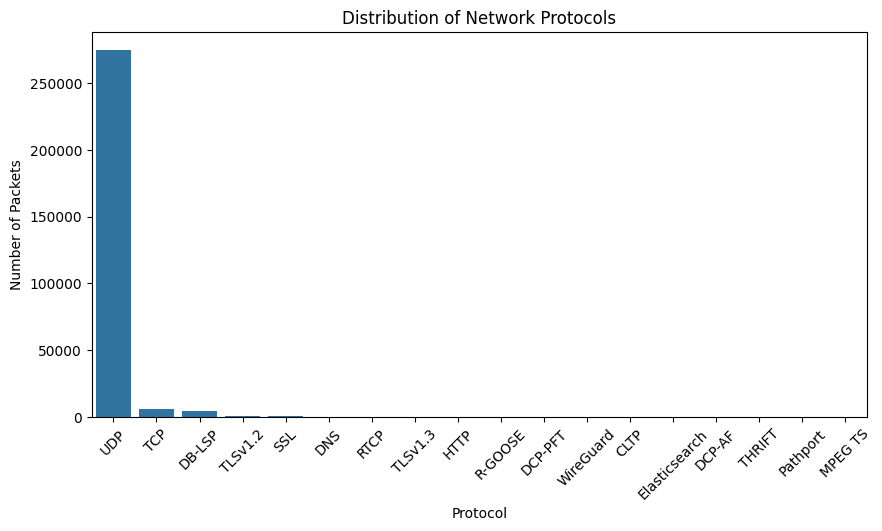

In [17]:
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")

plt.show()


In [18]:
df["Length"].describe()

,Length
count,286949.000000
mean,88.091825
std,209.757526
min,31.000000
25%,49.000000
50%,69.000000
75%,94.000000
max,10000.000000


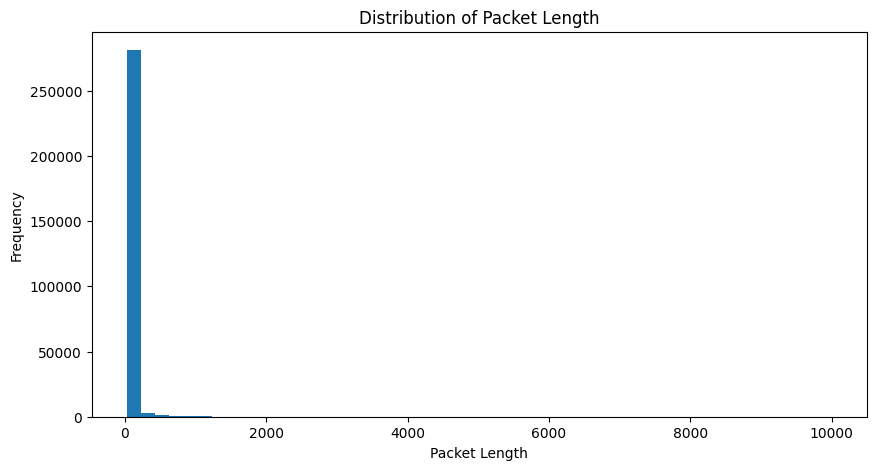

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(df["Length"], bins=50)

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")

plt.show()


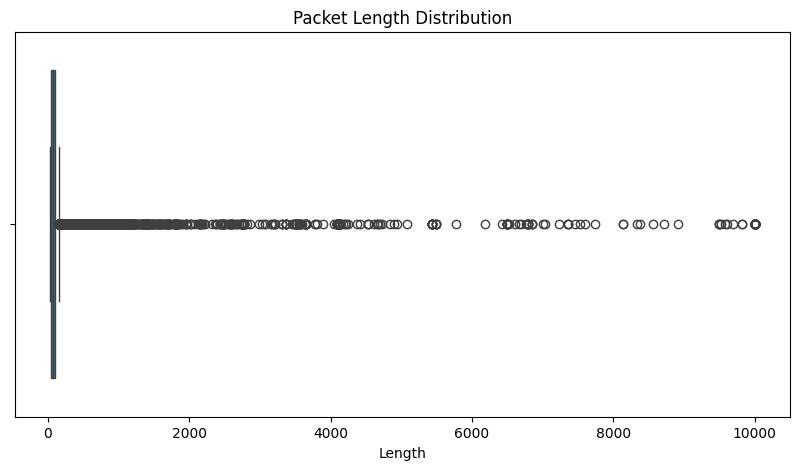

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Length"])

plt.title("Packet Length Distribution")

plt.show()

In [21]:
df["Time"].head()

,Time
0,2022-10-06 18:44:04.364036
1,2022-10-06 18:44:04.479088
2,2022-10-06 18:44:04.483528
3,2022-10-06 18:44:04.577833
4,2022-10-06 18:44:04.578007


In [22]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

In [23]:
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second


In [24]:
df[["Time", "Hour", "Minute", "Second"]].head()

,Time,Hour,Minute,Second
0,2022-10-06 18:44:04.364036,18,44,4
1,2022-10-06 18:44:04.479088,18,44,4
2,2022-10-06 18:44:04.483528,18,44,4
3,2022-10-06 18:44:04.577833,18,44,4
4,2022-10-06 18:44:04.578007,18,44,4


In [25]:
X = df[[
    "Length",
    "Hour",
    "Minute",
    "Second"
]]

y = df["Protocol"]


In [26]:
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   Length  Hour  Minute  Second
0      75    18      44       4
1     430    18      44       4
2      60    18      44       4
3      48    18      44       4
4      40    18      44       4

Target:
0    DNS
1    DNS
2    TCP
3    TCP
4    TCP
Name: Protocol, dtype: object


In [27]:
print("X shape:", X.shape)
print("y shape:", y.shape)



X shape: (286949, 4)
y shape: (286949,)


In [28]:
print(X.isnull().sum())

Length    0
Hour      0
Minute    0
Second    0
dtype: int64


In [29]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)


In [30]:
print(label_encoder.classes_)

['CLTP' 'DB-LSP' 'DCP-AF' 'DCP-PFT' 'DNS' 'Elasticsearch' 'HTTP' 'MPEG TS'
 'Pathport' 'R-GOOSE' 'RTCP' 'SSL' 'TCP' 'THRIFT' 'TLSv1.2' 'TLSv1.3'
 'UDP' 'WireGuard']


In [31]:
print(y_encoded[:20])



[ 4  4 12 12 12 14 12 14 12 14 12 14 14 12 14 12 12 16 16 16]


In [35]:
# Identify classes with only 1 sample
import numpy as np
class_counts = np.bincount(y_encoded)
valid_classes = np.where(class_counts >= 2)[0]

# Filter features and targets to keep only valid classes
mask = np.isin(y_encoded, valid_classes)
X_filtered = X[mask]
y_encoded_filtered = y_encoded[mask]

# Split the dataset using the filtered values
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_encoded_filtered,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered
)

In [36]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 229558
Testing samples: 57390


In [37]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


MODEL - 1

In [38]:
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)


LogisticRegression(max_iter=1000)

In [39]:
y_pred_lr = logistic_model.predict(X_test_scaled)

In [40]:
accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print("Logistic Regression Accuracy:",
      accuracy_lr)


Logistic Regression Accuracy: 0.9587384561770343


In [41]:
print(
    "Accuracy:",
    accuracy_lr * 100,
    "%"
)


Accuracy: 95.87384561770344 %


In [67]:
import numpy as np
# Retrieve original classes based on unique values in y
original_classes = np.array(df['Protocol'].unique())
original_classes.sort()

active_labels = np.unique(np.concatenate([y_test, y_pred_lr]))

print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=active_labels,
        target_names=original_classes[active_labels]
    )
)

               precision    recall  f1-score   support

         CLTP       0.00      0.00      0.00         1
       DB-LSP       0.51      0.19      0.27       921
       DCP-AF       0.00      0.00      0.00         1
      DCP-PFT       0.00      0.00      0.00         1
          DNS       0.00      0.00      0.00        78
Elasticsearch       0.00      0.00      0.00         1
         HTTP       0.00      0.00      0.00         4
      R-GOOSE       0.00      0.00      0.00         1
         RTCP       0.00      0.00      0.00        48
          SSL       0.00      0.00      0.00       129
          TCP       0.00      0.00      0.00      1168
      TLSv1.2       0.72      0.13      0.22       139
      TLSv1.3       0.00      0.00      0.00        24
          UDP       0.96      1.00      0.98     54873
    WireGuard       0.00      0.00      0.00         1

     accuracy                           0.96     57390
    macro avg       0.15      0.09      0.10     57390
 weighte

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


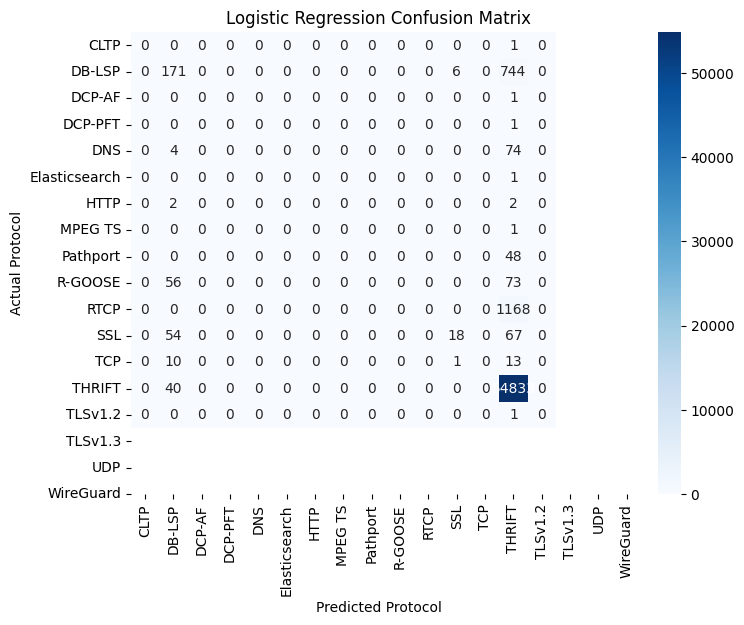

In [43]:
cm = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")

plt.show()


Model - 2

In [44]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)


KNeighborsClassifier()

In [45]:
y_pred_knn = knn_model.predict(
    X_test_scaled
)


In [46]:
accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print(
    "KNN Accuracy:",
    accuracy_knn * 100,
    "%"
)


KNN Accuracy: 97.39675901725039 %


Model - 3

In [47]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(
    X_train,
    y_train
)


DecisionTreeClassifier(max_depth=10, random_state=42)

In [48]:
y_pred_dt = dt_model.predict(X_test)

In [49]:
accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(
    "Decision Tree Accuracy:",
    accuracy_dt * 100,
    "%"
)


Decision Tree Accuracy: 97.99268165185573 %


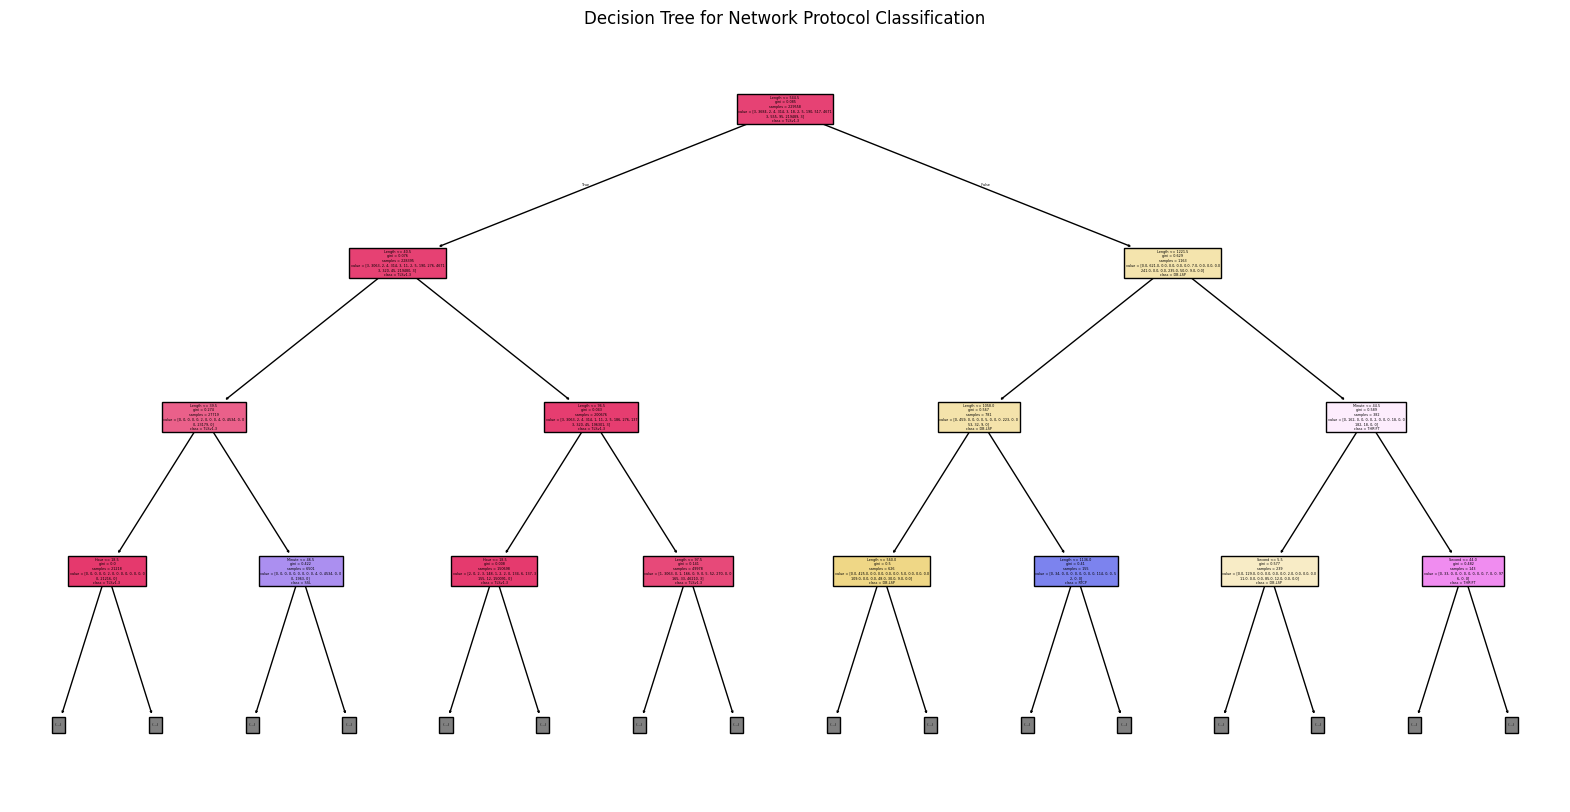

In [50]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3
)

plt.title("Decision Tree for Network Protocol Classification")

plt.show()


Model - 4

In [51]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)


RandomForestClassifier(n_jobs=-1, random_state=42)

In [52]:
y_pred_rf = rf_model.predict(X_test)

In [53]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    accuracy_rf * 100,
    "%"
)


Random Forest Accuracy: 98.60254399721205 %


Comparision between Model

In [54]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]
})

results["Accuracy (%)"] = (
    results["Accuracy"] * 100
)


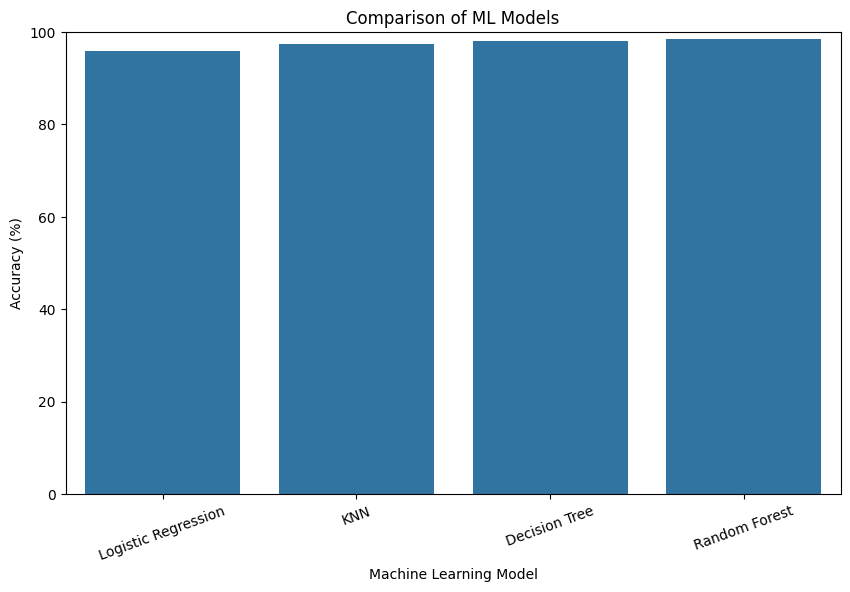

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.xticks(rotation=20)
plt.ylim(0, 100)

plt.title("Comparison of ML Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")

plt.show()


Best Model

In [56]:
best_model = results.loc[
    results["Accuracy"].idxmax()
]

print("Best Model:")
print(best_model)


Best Model:
Model           Random Forest
Accuracy             0.986025
Accuracy (%)        98.602544
Name: 3, dtype: object


In [57]:
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)


  Feature  Importance
0  Length    0.584238
2  Minute    0.206308
3  Second    0.185727
1    Hour    0.023727


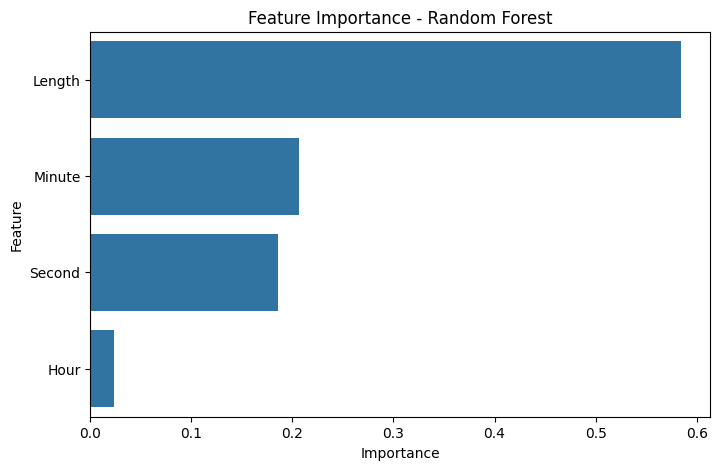

In [58]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")

plt.show()


In [64]:
# Update classes dynamically to match y_test so that target_names matches the classes present
import numpy as np
unique_test_classes = np.unique(y_test)
label_encoder.classes_ = label_encoder.classes_[unique_test_classes]

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=label_encoder.classes_
    )
)

               precision    recall  f1-score   support

         CLTP       0.00      0.00      0.00         1
       DB-LSP       0.81      0.85      0.83       921
       DCP-AF       0.00      0.00      0.00         1
      DCP-PFT       0.00      0.00      0.00         1
          DNS       0.69      0.59      0.63        78
Elasticsearch       0.00      0.00      0.00         1
         HTTP       0.00      0.00      0.00         4
      R-GOOSE       0.00      0.00      0.00         1
         RTCP       0.40      0.08      0.14        48
          SSL       0.85      0.47      0.60       129
          TCP       0.88      0.89      0.89      1168
      TLSv1.2       0.81      0.69      0.74       139
      TLSv1.3       0.56      0.42      0.48        24
          UDP       0.99      0.99      0.99     54873
    WireGuard       0.00      0.00      0.00         1

     accuracy                           0.99     57390
    macro avg       0.40      0.33      0.35     57390
 weighte

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


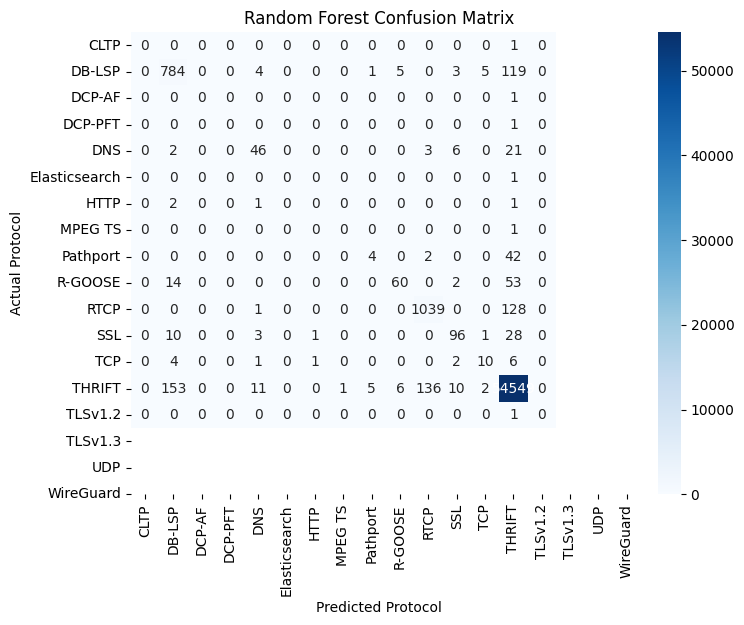

In [60]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

Predict new packet

In [61]:
new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})


In [62]:
prediction = rf_model.predict(
    new_packet
)


In [63]:
predicted_protocol = label_encoder.inverse_transform(
    prediction
)

print(
    "Predicted Protocol:",
    predicted_protocol[0]
)


Predicted Protocol: UDP
